# FPL Pipeline — Single Season Exploration
Runs the full data → features → model pipeline for a single season and explores the results.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from fplt.data import load_gameweeks, load_teams
from fplt.features import build_features
from fplt.predict import LGBMPredictor

DATA_DIR = Path("..") / "data"
TRAIN_SEASON = "2022-23"
TEST_SEASON  = "2023-24"

## 1. Load Data

In [2]:
gw_train  = load_gameweeks(TRAIN_SEASON, DATA_DIR)
gw_test   = load_gameweeks(TEST_SEASON,  DATA_DIR)
teams_train = load_teams(TRAIN_SEASON, DATA_DIR)
teams_test  = load_teams(TEST_SEASON,  DATA_DIR)

print(f"Train GWs: {gw_train['GW'].nunique()} | rows: {len(gw_train):,}")
print(f"Test  GWs: {gw_test['GW'].nunique()}  | rows: {len(gw_test):,}")
gw_train.head()

Train GWs: 37 | rows: 26,505
Test  GWs: 38  | rows: 29,725


,name,element,fixture,round,GW,kickoff_time,was_home,opponent_team,team_h_score,team_a_score,...,threat,position,team,xP,starts,expected_goals,expected_assists,expected_goal_involvements,expected_goals_conceded,season
0,Nathan Redmond,403,8,1,1,2022-08-06 14:00:00+00:00,False,18,4,1,...,0.0,MID,Southampton,1.5,0,0.0,0.0,0.0,0.0,2022-23
1,Junior Stanislas,58,2,1,1,2022-08-06 14:00:00+00:00,True,2,2,0,...,0.0,MID,Bournemouth,1.1,0,0.0,0.0,0.0,0.0,2022-23
2,Armando Broja,150,3,1,1,2022-08-06 16:30:00+00:00,False,8,0,1,...,19.0,FWD,Chelsea,2.0,0,0.0,0.0,0.0,0.0,2022-23
3,Fabian Schär,366,7,1,1,2022-08-06 14:00:00+00:00,True,16,2,0,...,25.0,DEF,Newcastle,2.4,0,0.0,0.0,0.0,0.0,2022-23
4,Jonny Evans,249,6,1,1,2022-08-07 13:00:00+00:00,True,4,2,2,...,0.0,DEF,Leicester,1.9,0,0.0,0.0,0.0,0.0,2022-23


## 2. Points Distribution

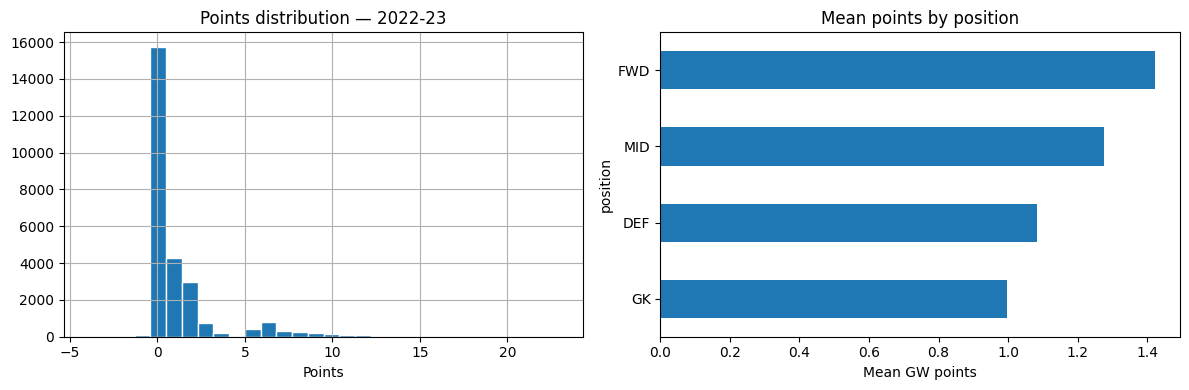

count    26505.000000
mean         1.196906
std          2.355236
min         -4.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         23.000000
Name: total_points, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

gw_train["total_points"].hist(bins=30, ax=axes[0], edgecolor="white")
axes[0].set_title(f"Points distribution — {TRAIN_SEASON}")
axes[0].set_xlabel("Points")

gw_train.groupby("position")["total_points"].mean().sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Mean points by position")
axes[1].set_xlabel("Mean GW points")

plt.tight_layout()
plt.show()

print(gw_train["total_points"].describe())

## 3. Build Features

In [4]:
df_train = build_features(gw_train, teams_train)
df_test  = build_features(gw_test,  teams_test)

# Drop GW1 — rolling features are all NaN
df_train = df_train[df_train["GW"] > 1].copy()
df_test  = df_test[df_test["GW"]  > 1].copy()

print(f"Train features shape: {df_train.shape}")
print(f"Test  features shape: {df_test.shape}")

# Preview rolling features for one player
player = df_train[df_train["name"].str.contains("Salah", case=False)]
player[["name", "GW", "total_points", "total_points_rolling_3", "total_points_rolling_5", "minutes_rolling_5"]].head(10)

Train features shape: (25932, 104)
Test  features shape: (29067, 104)


,name,GW,total_points,total_points_rolling_3,total_points_rolling_5,minutes_rolling_5
10715,Mohamed Salah,2,2,12.000000,12.000000,90.0
10716,Mohamed Salah,3,8,7.000000,7.000000,90.0
10717,Mohamed Salah,4,3,7.333333,7.333333,90.0
10718,Mohamed Salah,5,10,4.333333,6.250000,90.0
10719,Mohamed Salah,6,3,7.000000,7.000000,90.0
10720,Mohamed Salah,9,5,5.333333,5.200000,90.0
10721,Mohamed Salah,10,2,6.000000,5.800000,90.0
10722,Mohamed Salah,11,8,3.333333,4.600000,85.6
10723,Mohamed Salah,12,3,5.000000,5.600000,85.4
10724,Mohamed Salah,13,2,4.333333,4.200000,85.4


## 4. Train Model

In [5]:
X_train = df_train
y_train = df_train["total_points"]
X_test  = df_test
y_test  = df_test["total_points"]

model = LGBMPredictor(num_rounds=500)
model.fit(X_train, y_train, X_val=X_test, y_val=y_test)

print(f"Features used: {len(model.feature_cols)}")
print(model.feature_cols)

Features used: 33
['position_enc', 'was_home', 'value', 'opponent_team', 'opp_strength_overall', 'opp_strength_attack', 'opp_strength_defence', 'total_points_rolling_3', 'total_points_rolling_5', 'total_points_rolling_10', 'minutes_rolling_3', 'minutes_rolling_5', 'minutes_rolling_10', 'minutes_std_5', 'goals_scored_rolling_5', 'assists_rolling_5', 'clean_sheets_rolling_5', 'goals_conceded_rolling_5', 'saves_rolling_5', 'bonus_rolling_5', 'bps_rolling_5', 'ict_index_rolling_5', 'threat_rolling_5', 'creativity_rolling_5', 'influence_rolling_5', 'xP_rolling_3', 'xP_rolling_5', 'xP_rolling_10', 'starts_rolling_5', 'expected_goals_rolling_5', 'expected_assists_rolling_5', 'expected_goal_involvements_rolling_5', 'expected_goals_conceded_rolling_5']


## 5. Evaluate

In [6]:
preds = model.predict(X_test)

mae  = np.mean(np.abs(preds - y_test.to_numpy()))
rmse = np.sqrt(np.mean((preds - y_test.to_numpy()) ** 2))

baseline_mae = np.mean(np.abs(y_train.mean() - y_test.to_numpy()))

print(f"MAE:          {mae:.3f}")
print(f"RMSE:         {rmse:.3f}")
print(f"Baseline MAE: {baseline_mae:.3f}  (predict mean)")
print(f"Improvement:  {(1 - mae / baseline_mae) * 100:.1f}%")

MAE:          0.955
RMSE:         1.938
Baseline MAE: 1.476  (predict mean)
Improvement:  35.2%


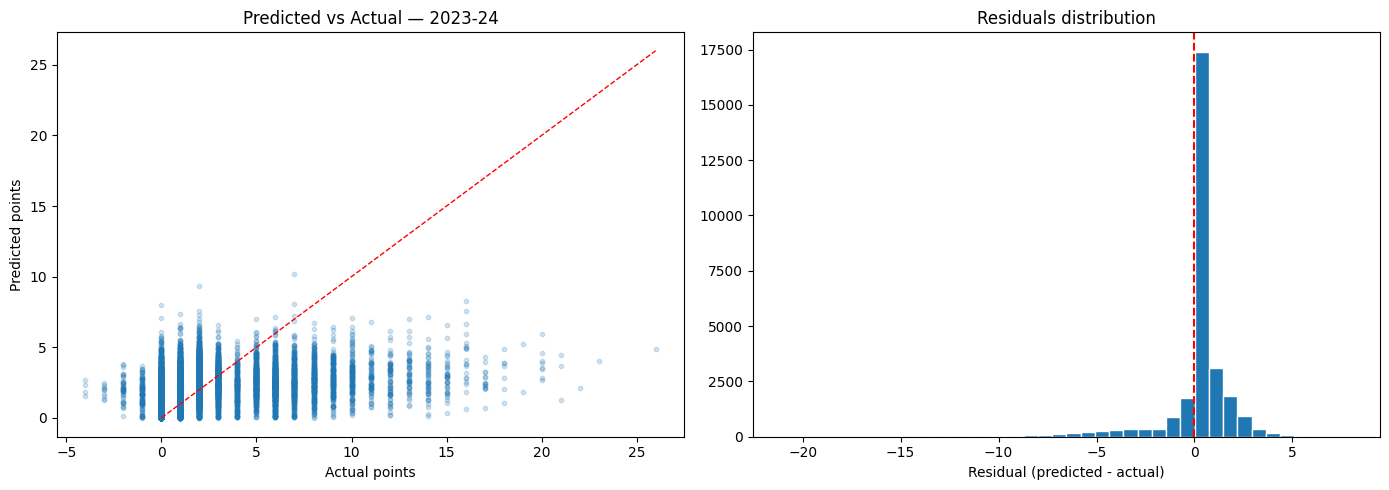

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Predicted vs actual scatter
axes[0].scatter(y_test, preds, alpha=0.2, s=10)
lim = max(y_test.max(), preds.max())
axes[0].plot([0, lim], [0, lim], "r--", linewidth=1)
axes[0].set_xlabel("Actual points")
axes[0].set_ylabel("Predicted points")
axes[0].set_title(f"Predicted vs Actual — {TEST_SEASON}")

# Residuals
residuals = preds - y_test.to_numpy()
axes[1].hist(residuals, bins=40, edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual (predicted - actual)")
axes[1].set_title("Residuals distribution")

plt.tight_layout()
plt.show()

## 6. Feature Importance

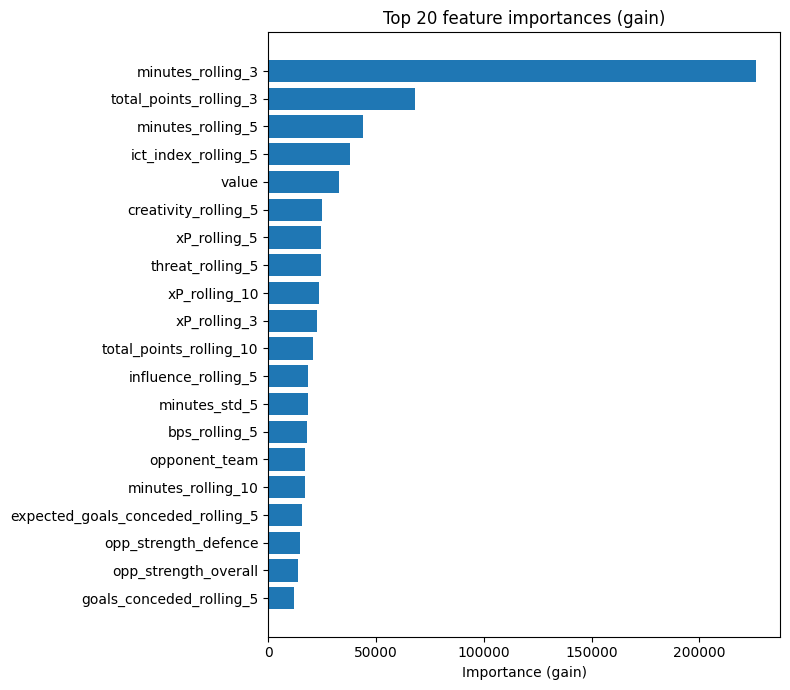

,feature,importance
0,minutes_rolling_3,226140.742069
1,total_points_rolling_3,67942.705495
2,minutes_rolling_5,43856.047207
3,ict_index_rolling_5,37674.608689
4,value,32718.711514
5,creativity_rolling_5,24806.934711
6,xP_rolling_5,24601.762623
7,threat_rolling_5,24274.238136
8,xP_rolling_10,23360.557782
9,xP_rolling_3,22575.272030


In [8]:
fi = model.feature_importance().head(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(fi["feature"][::-1], fi["importance"][::-1])
ax.set_title("Top 20 feature importances (gain)")
ax.set_xlabel("Importance (gain)")
plt.tight_layout()
plt.show()

fi

## 7. Top Predicted Players — Next GW

In [9]:
# Use the last available GW in the test season as a proxy for "current state"
last_gw = df_test["GW"].max()
current = df_test[df_test["GW"] == last_gw].copy()
current["predicted_points"] = model.predict(current)

top = (
    current[["name", "position", "team", "value", "predicted_points"]]
    .sort_values("predicted_points", ascending=False)
    .head(20)
    .reset_index(drop=True)
)
top["value"] = top["value"] / 10  # convert to £m
top

,name,position,team,value,predicted_points
0,Erling Haaland,FWD,Man City,14.3,9.323879
1,Kevin De Bruyne,MID,Man City,10.6,7.024996
2,Mohamed Salah,MID,Liverpool,13.4,6.341883
3,Leandro Trossard,MID,Arsenal,6.6,6.315035
4,Nicolas Jackson,FWD,Chelsea,7.0,6.187899
5,Joško Gvardiol,DEF,Man City,5.2,6.041155
6,Noni Madueke,MID,Chelsea,5.3,6.004048
7,Trent Alexander-Arnold,DEF,Liverpool,8.4,5.843655
8,Bukayo Saka,MID,Arsenal,8.8,5.651903
9,Phil Foden,MID,Man City,8.5,5.637742
